# Can I fly? Real METAR reports and wind at flight height

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/drone_weather_en.ipynb)

**OpenSkyLab · notebook for the visual** [Can I fly? Weather for drones](https://openskylab.space/edu_viz_drone_weather.html) · [česká verze](drone_weather_cs.ipynb)

In the visual you decoded example METAR reports, converted the airport wind to the flight site and height and decided with a traffic light. Here you download real METAR reports from Czech airports for the last 24 hours, decode them yourself and compare the result with a model forecast of wind at 80 and 120 m.

**Goal:** decode METAR, compute relative humidity and an estimate of the cloud base, convert the 10 m wind to flight height over different terrain, estimate the return against the wind, and decide about flying over the next 24 hours.

**Data:** METAR and TAF reports from Prague (LKPR), Brno (LKTB), Ostrava (LKMT) and Karlovy Vary (LKKV) airports from the NOAA Aviation Weather Center; an hourly forecast from Open-Meteo for Roztoky u Prahy. The data change every half hour, so your numbers will differ from the stored notebook.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and real METAR reports

In [1]:
import re, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

In [2]:
STATIONS = "LKPR,LKTB,LKMT,LKKV"          # ◀ parameter: ICAO airport codes
raw = requests.get("https://aviationweather.gov/api/data/metar", params={"ids": STATIONS, "format": "raw", "hours": 24}, timeout=60).text.strip().splitlines()
taf = requests.get("https://aviationweather.gov/api/data/taf", params={"ids": "LKPR", "format": "raw"}, timeout=60).text.strip()
print(f"{len(raw)} reports; latest:"); print("\n".join(raw[:6])); print("\nTAF Prague:\n" + taf)

181 reports; latest:
METAR LKTB 282330Z 33007KT 9999 OVC025 09/05 Q1025 NOSIG
METAR LKTB 282300Z 33009KT 9999 OVC026 09/05 Q1025 NOSIG
METAR LKTB 282230Z 33007KT 9999 SCT036 OVC048 09/05 Q1025 NOSIG
METAR LKTB 282200Z 35005KT 320V020 9999 OVC042 09/04 Q1025 NOSIG
METAR LKTB 282130Z 35005KT 320V020 9999 OVC046 09/04 Q1025 NOSIG
METAR LKTB 282100Z 33009KT 9999 FEW049 09/04 Q1025 NOSIG

TAF Prague:
TAF LKPR 282300Z 2900/3006 32007KT 9999 SCT013 OVC017 
  TEMPO 2900/2902 BKN013 
  BECMG 2904/2906 CAVOK 
  BECMG 2920/2922 31004KT 2500 BR SCT003 
  BECMG 2922/2924 1200 BR SCT002 BKN012 
  TEMPO 3000/3006 0700 -DZ FG OVC002


## 2. Your own decoder

A report has a fixed order of groups: airport, time, wind (direction, speed, gusts G), visibility in metres or CAVOK, weather (RA rain, SN snow, BR mist, FG fog, - light, + heavy), cloud (FEW, SCT, BKN, OVC and height in hundreds of feet), temperature/dew point (M = minus) and QNH pressure. The part after TEMPO, BECMG or NOSIG is a short trend forecast and the decoder skips it.

In [3]:
KT = 0.514444
def decode(m):
    body = re.split(r"\b(TEMPO|BECMG|NOSIG|RMK)\b", m)[0]
    d = {"station": body.split()[1], "time": re.search(r"\b(\d{6})Z\b", body).group(1)}
    w = re.search(r"\b(\d{3}|VRB)(\d{2,3})(?:G(\d{2,3}))?(KT|MPS)\b", body)
    if w:
        f = KT if w.group(4) == "KT" else 1.0
        d["dir"] = w.group(1); d["wind m/s"] = int(w.group(2)) * f; d["gusts m/s"] = int(w.group(3)) * f if w.group(3) else np.nan
    if "CAVOK" in body:
        d["visibility m"] = 10000
    else:
        v = re.search(r"(?<=KT )(\d{4})\b|(?<=MPS )(\d{4})\b|\s(\d{4})\s", body)
        d["visibility m"] = int(next(g for g in v.groups() if g)) if v else np.nan
    d["weather"] = " ".join(re.findall(r"(?<=\s)([-+]?(?:VC)?(?:MI|BC|PR|DR|BL|SH|TS|FZ)?(?:DZ|RA|SN|SG|PL|GR|GS|BR|FG|FU|HZ|SQ)+)(?=\s)", body + " "))
    clouds = re.findall(r"\b(FEW|SCT|BKN|OVC|VV)(\d{3})", body)
    d["cloud"] = " ".join(f"{c}{int(h) * 100}ft" for c, h in clouds)
    ceil = [int(h) * 100 * 0.3048 for c, h in clouds if c in ("BKN", "OVC", "VV")]
    d["BKN/OVC base m"] = min(ceil) if ceil else np.nan
    tt = re.search(r"\b(M?\d{2})/(M?\d{2})\b", body)
    if tt:
        d["T °C"], d["Td °C"] = (int(x.replace("M", "-")) for x in tt.groups())
    return d

met = pd.DataFrame([decode(m) for m in raw])
met["RH %"] = 100 * np.exp(17.62 * met["Td °C"] / (243.12 + met["Td °C"])) / np.exp(17.62 * met["T °C"] / (243.12 + met["T °C"]))
met["estimated base m"] = 125 * (met["T °C"] - met["Td °C"])
met.head(12).round(1)

,station,time,dir,wind m/s,gusts m/s,visibility m,weather,cloud,BKN/OVC base m,T °C,Td °C,RH %,estimated base m
0,LKTB,282330,330,3.6,NaN,9999,,OVC2500ft,762.0,9,5,76.0,500
1,LKTB,282300,330,4.6,NaN,9999,,OVC2600ft,792.5,9,5,76.0,500
2,LKTB,282230,330,3.6,NaN,9999,,SCT3600ft OVC4800ft,1463.0,9,5,76.0,500
3,LKTB,282200,350,2.6,NaN,9999,,OVC4200ft,1280.2,9,4,70.9,625
4,LKTB,282130,350,2.6,NaN,9999,,OVC4600ft,1402.1,9,4,70.9,625
5,LKTB,282100,330,4.6,NaN,9999,,FEW4900ft,NaN,9,4,70.9,625
6,LKTB,282030,330,3.6,NaN,9999,,FEW4800ft,NaN,9,4,70.9,625
7,LKTB,282000,320,2.6,NaN,9999,,BKN4800ft,1463.0,9,4,70.9,625
8,LKTB,281930,330,3.6,NaN,9999,,BKN4700ft,1432.6,10,4,66.3,750
9,LKTB,281900,300,3.1,NaN,9999,,OVC4700ft,1432.6,9,4,70.9,625


> **✏️ Task 1.** Pick one report and decode it by hand group by group; does it agree with the table? Which groups alone would rule out a VLOS flight (visibility, fog, low cloud, precipitation)? Why is the difference T − Td more important to a pilot than the temperature alone?

*Your answer:* 

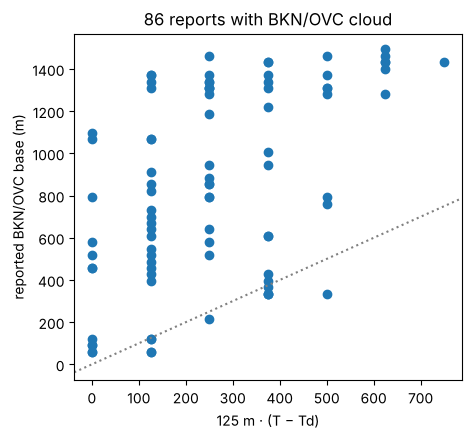

In [4]:
c = met.dropna(subset=["BKN/OVC base m"])
plt.figure(figsize=(5, 4.5))
plt.scatter(c["estimated base m"], c["BKN/OVC base m"])
plt.axline((0, 0), slope=1, color="gray", ls=":")
plt.xlabel("125 m · (T − Td)"); plt.ylabel("reported BKN/OVC base (m)"); plt.title(f"{len(c)} reports with BKN/OVC cloud"); plt.show()

> **✏️ Task 2.** How well does the estimate 125 m · (T − Td) match the reported cloud base? The estimate holds for cumulus in a well-mixed daytime layer. Find reports where it fails and explain why (night, stratiform cloud, inversion, cloud from another air mass).

*Your answer:* 

## 3. Wind at flight height over different terrain

Airports measure wind 10 m above grass (roughness length z0 = 0.03 m). At a blending height of 60 m the surface hardly matters, so we transfer the wind there to the flight site with a different roughness z0 and zero-plane displacement d (Wieringa 1986). This holds for neutral stratification (windy, overcast); on a sunny day or at night the profile differs.

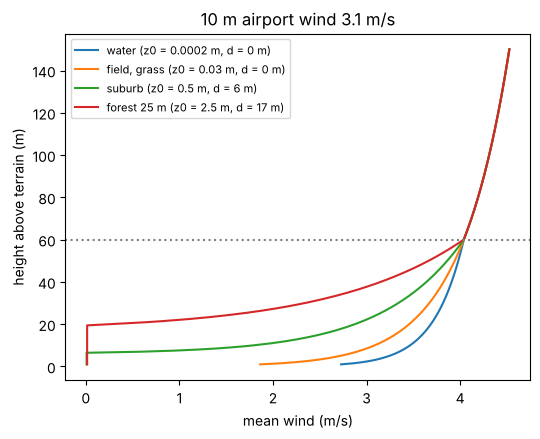

water       : 30 m  3.8 m/s, 100 m  4.3 m/s
field, grass: 30 m  3.7 m/s, 100 m  4.3 m/s
suburb      : 30 m  3.3 m/s, 100 m  4.3 m/s
forest 25 m : 30 m  2.3 m/s, 100 m  4.3 m/s


In [5]:
def wind_at(z, u10, z0=0.03, d=0.0, zb=60.0):
    ub = u10 * np.log(zb / 0.03) / np.log(10 / 0.03)                    # wind at the blending height above the airport
    z = np.asarray(z, float)
    site = ub * np.log(np.maximum(z - d, z0 * 1.01) / z0) / np.log((zb - d) / z0)
    above = ub * np.log(z / 0.03) / np.log(zb / 0.03)
    return np.where(z <= zb, site, above)

TERRAIN = {"water": (0.0002, 0), "field, grass": (0.03, 0), "suburb": (0.5, 6), "forest 25 m": (2.5, 17)}
u10 = float(met[met["station"] == "LKPR"]["wind m/s"].iloc[0])     # ◀ parameter: wind at 10 m (default is the latest Prague METAR)
z = np.linspace(1, 150, 300)
plt.figure(figsize=(6, 4.5))
for name, (z0, d) in TERRAIN.items():
    plt.plot(wind_at(z, u10, z0, d), z, label=f"{name} (z0 = {z0} m, d = {d} m)")
plt.axhline(60, color="gray", ls=":"); plt.xlabel("mean wind (m/s)"); plt.ylabel("height above terrain (m)")
plt.title(f"10 m airport wind {u10:.1f} m/s"); plt.legend(fontsize=8); plt.show()
for name, (z0, d) in TERRAIN.items():
    print(f"{name:12s}: 30 m {wind_at(30, u10, z0, d):4.1f} m/s, 100 m {wind_at(100, u10, z0, d):4.1f} m/s")

In [6]:
fc = open_meteo({"latitude": 50.152, "longitude": 14.392, "forecast_days": 2, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                 "hourly": "wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_gusts_10m,temperature_2m,dew_point_2m,visibility,precipitation"})
fc = pd.DataFrame(fc["hourly"]).set_index("time")
ratio80 = (fc.wind_speed_80m / fc.wind_speed_10m)[fc.wind_speed_10m > 2]
print(f"Open-Meteo for Roztoky: wind ratio 80 m / 10 m median {ratio80.median():.2f} (range {ratio80.min():.2f}–{ratio80.max():.2f})")
print(f"our profile over a field: {wind_at(80, 1.0, 0.03, 0) / 1.0:.2f}, over a suburb: {wind_at(80, 1.0, 0.5, 6) / wind_at(10, 1.0, 0.5, 6):.2f}")

Open-Meteo: SSLError – retrying


Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


Open-Meteo for Roztoky: wind ratio 80 m / 10 m median 1.32 (range 1.15–1.97)
our profile over a field: 1.36, over a suburb: 2.34


> **✏️ Task 3.** Why is the mean wind at 30 m weaker over forest than over water, but almost the same at 100 m? A colleague says: "The airport reports 6 m/s, the drone handles 12 m/s, we have a twofold margin." Set `u10 = 6` and answer with numbers for 100 m. How does the 80 m / 10 m ratio from the Open-Meteo model differ from our profile and why (stability during day and night)?

*Your answer:* 

## 4. The way back against the wind

The drone flies at airspeed V, the wind at flight height is U. Over a distance D downwind out and upwind back the flight takes t = D/(V + U) + D/(V − U).

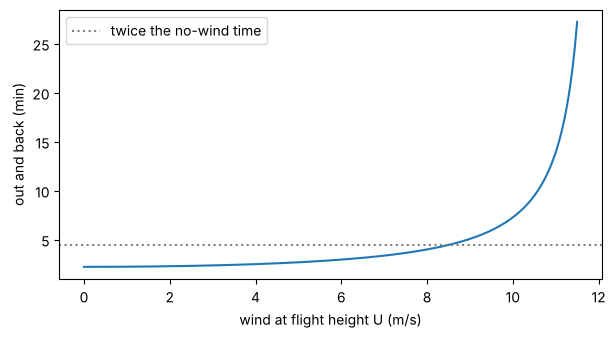

no wind 2.2 min; doubled at U = 8.5 m/s


In [7]:
V, D = 12.0, 800          # ◀ parameter: airspeed (m/s) and distance from the pilot (m)
U = np.linspace(0, 11.5, 200)
t_rt = D / (V + U) + D / (V - U)
plt.figure(figsize=(7, 3.5)); plt.plot(U, t_rt / 60); plt.axhline(2 * D / V / 60 * 2, color="gray", ls=":", label="twice the no-wind time")
plt.xlabel("wind at flight height U (m/s)"); plt.ylabel("out and back (min)"); plt.legend(); plt.show()
print(f"no wind {2 * D / V / 60:.1f} min; doubled at U = {V / np.sqrt(2):.1f} m/s")

> **✏️ Task 4.** Derive from the formula at what wind the round-trip time doubles (the cell prints U = V/√2). Why is it not enough that the mean wind at flight height is below the drone's wind resistance when gusts (the gust column in METAR) are 30–50 % higher? How would you plan the route accordingly?

*Your answer:* 

## 5. A traffic light for the next 48 hours

For each hour of the Open-Meteo forecast for Roztoky we decide: wind at 120 m and gusts against the drone's limit, precipitation, visibility and icing risk (temperature below 1 °C and T − Td within 2 °C).

In [8]:
limit = 12.0               # ◀ parameter: drone wind resistance (m/s)
gust_factor = (fc.wind_gusts_10m / fc.wind_speed_10m.clip(lower=1)).clip(upper=2.5)
wind_fl = fc.wind_speed_120m
gust_fl = wind_fl * gust_factor
red = (gust_fl > limit) | (fc.precipitation > 0.5) | (fc.visibility < 1000)
icing = (fc.temperature_2m < 1) & (fc.temperature_2m - fc.dew_point_2m <= 2)
yellow = ~red & ((gust_fl > 0.75 * limit) | (fc.precipitation > 0) | (fc.visibility < 5000) | icing)
status = np.where(red, "NO GO", np.where(yellow, "caution", "ok"))
out = pd.DataFrame({"wind 120 m": wind_fl, "gusts ~": gust_fl, "precip. mm": fc.precipitation, "visibility km": fc.visibility / 1000,
                    "T": fc.temperature_2m, "T−Td": fc.temperature_2m - fc.dew_point_2m, "verdict": status}).round(1)
colors = {"ok": "#cfe8cf", "caution": "#ffe7a3", "NO GO": "#f4b6b6"}
out.style.apply(lambda r: [f"background-color: {colors[r['verdict']]}"] * len(r), axis=1)

,wind 120 m,gusts ~,precip. mm,visibility km,T,T−Td,verdict
time,,,,,,,
2026-10-29T00:00,5.900000,11.500000,0.000000,25.000000,9.400000,1.800000,caution
2026-10-29T01:00,5.500000,11.500000,0.000000,24.100000,9.200000,1.800000,caution
2026-10-29T02:00,5.000000,10.100000,0.000000,23.400000,9.000000,1.700000,caution
2026-10-29T03:00,4.400000,8.800000,0.000000,22.600000,8.400000,1.600000,ok
2026-10-29T04:00,4.700000,8.300000,0.000000,23.300000,7.900000,1.700000,ok
2026-10-29T05:00,4.100000,9.300000,0.000000,22.200000,7.100000,1.500000,caution
2026-10-29T06:00,3.900000,8.500000,0.000000,19.400000,6.100000,1.200000,ok
2026-10-29T07:00,3.900000,6.600000,0.000000,14.200000,5.100000,0.700000,ok
2026-10-29T08:00,4.100000,7.300000,0.000000,13.800000,5.400000,0.700000,ok


> **✏️ Task 5.** When would you fly in the next 48 hours and what decides the other hours? Compare the forecast with the latest TAF for Prague: do they agree? We estimated gusts at 120 m from the gust-to-wind ratio at 10 m; why is that rough, and is the result on the safe side or not? Set `limit = 10.7` (drones under 250 g).

*Your answer:* 

---
### Data sources and references

- METAR and TAF: NOAA/NWS Aviation Weather Center, https://aviationweather.gov/data/api/ (US government public data).
- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Relative humidity and saturation vapour pressure (Magnus formula): WMO (2018). *Guide to Instruments and Methods of Observation* (WMO-No. 8), annex 4.B.
- Wind transfer via a 60 m blending height: Wieringa, J. (1986). Roughness-dependent geographical interpolation of surface wind speed averages. *Quarterly Journal of the Royal Meteorological Society* 112, 867–889; Verkaik, J. W. (2000). Evaluation of two gustiness models for exposure correction calculations. *Journal of Applied Meteorology* 39, 1613–1626.
- METAR code: ICAO Annex 3 / WMO-No. 306, code FM 15.
- DJI Mavic 3 Enterprise wind resistance 12 m/s, max. speed 15 m/s (DJI data sheet).

### How to cite

OpenSkyLab (2026). Can I fly? Real METAR reports and wind at flight height [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/drone_weather_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*